# 02 - Early prototypes (exp_000-003)

Historical notebook for the first optimizer, BatchNorm, and validation-protocol prototypes.
These runs are marked `LEGACY` and excluded from the main tables, but are kept for provenance
and to document the seed-42 collapse.

**How to run:** top to bottom from `task_a/notebooks/`. These cells retrain models and write
to `task_a/runs/`; they are not needed to reproduce the final report.


## Setup - imports, device, and seeds

In [5]:
%load_ext autoreload
%autoreload 2
# Make `src` importable
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

# Project modules
from src.config import PROJECT_ROOT, DATA_DIR, RUNS_DIR, SEED, CIFAR100_MEAN, CIFAR100_STD
from src.models import baseline_cnn, baseline_cnn_bn
from src.data import build_datasets, build_loaders, build_loaders_val
from src.engine import train_one_epoch, evaluate, fit
from src.utils import set_seed, save_run

import torch
from torchinfo import summary

# Train on GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

# Fix all RNG seeds BEFORE the model and the DataLoaders are created
set_seed(SEED)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
cuda NVIDIA GeForce RTX 4060 Laptop GPU


## exp_001 - Adam instead of SGD (full 50k protocol)

In [2]:
# exp_001: optimizer factor - Adam(lr=1e-3) vs exp_000's SGD(lr=1e-2). Everything else identical.
set_seed(SEED)                                        # same seed protocol, before model creation

train_loader, test_loader = build_loaders(batch_size=128)

model_adam = baseline_cnn().to(device)                # fresh model; separate names keep exp_000 intact
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_adam.parameters(), lr=1e-3)

history_adam = fit(model_adam, train_loader, test_loader,
                    criterion, optimizer, epochs=10, device=device)

epoch  1/10 | train 4.386/0.028 | test 4.225/0.047 | 141s
epoch  2/10 | train 4.060/0.073 | test 3.907/0.093 | 142s
epoch  3/10 | train 3.747/0.122 | test 3.582/0.144 | 141s
epoch  4/10 | train 3.486/0.165 | test 3.482/0.165 | 141s
epoch  5/10 | train 3.303/0.200 | test 3.261/0.207 | 141s
epoch  6/10 | train 3.161/0.229 | test 3.142/0.238 | 141s
epoch  7/10 | train 3.056/0.249 | test 3.130/0.235 | 141s
epoch  8/10 | train 2.960/0.270 | test 2.991/0.260 | 142s
epoch  9/10 | train 2.877/0.287 | test 2.934/0.275 | 141s
epoch 10/10 | train 2.788/0.302 | test 2.827/0.293 | 141s


## Save exp_001

saved -> C:\Users\sigridwicks\Desktop\DL HW1\runs\exp_001_adam
final test acc: 0.2928
epoch times  : [141, 142, 141, 141, 141, 141, 141, 142, 141, 141]


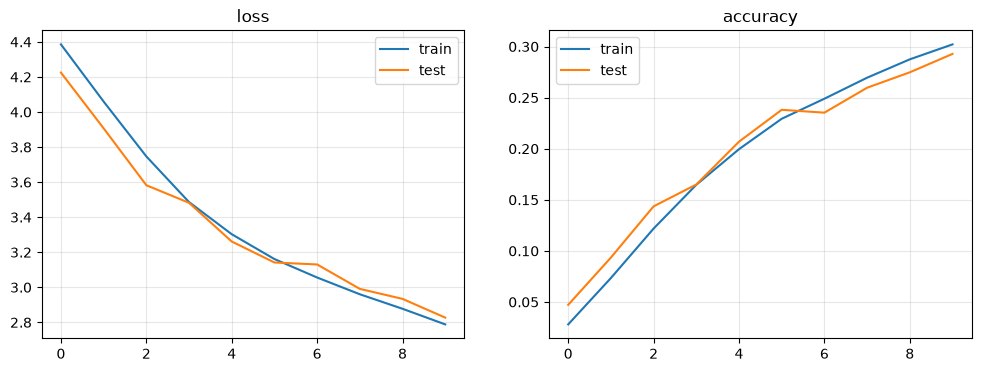

In [3]:
import json, csv
import matplotlib.pyplot as plt

run_dir = RUNS_DIR / "exp_001_adam"
run_dir.mkdir(parents=True, exist_ok=True)

config = {"arch": "baseline", "optimizer": "Adam", "lr": 1e-3, "epochs": 10,
        "batch": 128, "aug": "none", "seed": SEED, "vs": "exp_000_baseline (SGD 1e-2)"}
(run_dir / "config.json").write_text(json.dumps(config, indent=2))

with open(run_dir / "metrics.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["epoch", "train_loss", "train_acc", "test_loss", "test_acc", "epoch_time"])
    for i in range(len(history_adam["train_loss"])):
        w.writerow([i + 1, history_adam["train_loss"][i], history_adam["train_acc"][i],
                    history_adam["test_loss"][i], history_adam["test_acc"][i],
                    round(history_adam["epoch_time"][i], 1)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_adam["train_loss"], label="train"); ax1.plot(history_adam["test_loss"],
label="test")
ax1.set_title("loss"); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(history_adam["train_acc"], label="train"); ax2.plot(history_adam["test_acc"],
label="test")
ax2.set_title("accuracy"); ax2.legend(); ax2.grid(alpha=0.3)
fig.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")

torch.save(model_adam.state_dict(), run_dir / "model.pt")

print("saved ->", run_dir)
print("final test acc:", history_adam["test_acc"][-1])
print("epoch times  :", [round(t) for t in history_adam["epoch_time"]])

## exp_002 - Adam under the 45k/5k validation protocol

In [7]:
# exp_002: Adam 1e-3 under the val protocol (45k train / 5k val) - control run for exp_003+
# NOTE: with seed 42 this exact setup collapsed to the constant predictor (loss pinned at ln 100,
# logits std 0.000, accuracy = chance). Seed 0 is verified healthy on this data order;
# exp_002 and exp_003 both use seed 0 for a clean A/B.
set_seed(0)

train_loader, val_loader, test_loader = build_loaders_val(batch_size=128)

model_002 = baseline_cnn().to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_002.parameters(), lr=1e-3)

history_002 = fit(model_002, train_loader, val_loader, criterion, optimizer,
                  epochs=10, device=device)

config_002 = {"arch": "baseline", "optimizer": "Adam", "lr": 1e-3, "epochs": 10, "batch": 128,
              "aug": "none", "seed": 0, "eval_set": "val5k",
              "note": "control for the 45k val protocol; seed 0 (the seed-42 attempt collapsed to chance)"}
save_run("exp_002_adam_45k", history_002, model_002, config_002)

epoch  1/10 | train 4.393/0.026 | test 4.175/0.052 | 126s
epoch  2/10 | train 3.968/0.087 | test 3.781/0.120 | 123s
epoch  3/10 | train 3.638/0.141 | test 3.535/0.157 | 123s
epoch  4/10 | train 3.429/0.176 | test 3.336/0.195 | 123s
epoch  5/10 | train 3.280/0.203 | test 3.213/0.212 | 121s
epoch  6/10 | train 3.161/0.231 | test 3.129/0.235 | 123s
epoch  7/10 | train 3.060/0.251 | test 3.028/0.250 | 123s
epoch  8/10 | train 2.968/0.270 | test 2.913/0.273 | 123s
epoch  9/10 | train 2.879/0.286 | test 2.869/0.279 | 120s
epoch 10/10 | train 2.811/0.300 | test 2.854/0.279 | 119s
saved -> C:\Users\sigridwicks\Desktop\DL HW1\runs\exp_002_adam_45k | final acc: 0.2794


WindowsPath('C:/Users/sigridwicks/Desktop/DL HW1/runs/exp_002_adam_45k')

## exp_003 - Add BatchNorm under the validation protocol

In [ ]:
# exp_003: +BatchNorm on the winning recipe (Adam 1e-3, val protocol). Single change vs exp_002.
# Seed 0 matches exp_002 (clean A/B). BN is expected to be robust where the no-BN run collapsed.
set_seed(0)

# Loaders can be reused if exp_002 just ran; rebuild here so the cell also works after a restart
train_loader, val_loader, test_loader = build_loaders_val(batch_size=128)

model_003 = baseline_cnn_bn().to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_003.parameters(), lr=1e-3)

history_003 = fit(model_003, train_loader, val_loader, criterion, optimizer,
                  epochs=10, device=device)

config_003 = {"arch": "baseline+BN", "optimizer": "Adam", "lr": 1e-3, "epochs": 10, "batch": 128,
              "aug": "none", "seed": 0, "eval_set": "val5k",
              "note": "BN after every Conv (before ReLU); lr NOT rescaled yet - try 3e-3 next"}
save_run("exp_003_adam_bn", history_003, model_003, config_003)

## Early-run summary table

In [ ]:
import json
import pandas as pd
from src.config import RUNS_DIR

# Manually maintained: what each early experiment changed (provenance for the report).
notes = {
    "exp_000_baseline": "baseline (SGD 1e-2, 50k, seed 42)",
    "exp_001_adam": "optimizer -> Adam 1e-3 (50k, seed 42)",
    "exp_002_adam_45k": "val-protocol control (Adam 1e-3, 45k, seed 0)",
    "exp_003_adam_bn": "+BatchNorm (Adam 1e-3, 45k, seed 0)",
}

rows = []
for d in sorted(RUNS_DIR.glob("exp_*")):
    cfg = json.loads((d / "config.json").read_text())
    m = pd.read_csv(d / "metrics.csv")
    last = m["test_acc"].iloc[-1]      # this column holds val accuracy when eval_set == "val5k"
    rows.append({
        "exp_id": d.name,
        "change": notes.get(d.name, ""),
        "epochs": cfg.get("epochs"), "batch": cfg.get("batch"), "lr": cfg.get("lr"),
        "optimizer": cfg.get("optimizer"), "aug": cfg.get("aug"), "seed": cfg.get("seed"),
        "eval_set": cfg.get("eval_set", "test_10k"),
        "top1": round(last, 4),
        "delta_vs_exp_000": f"{(last - 0.1182) * 100:+.2f}",   # 0.1182 = exp_000 test top1
    })

df = pd.DataFrame(rows)
display(df)
# For the report: df.to_markdown()  (needs `pip install tabulate`) or df.to_latex()
